# 01 · Radiation reference: how does ARGUS compare with measured spaceflight doses?

**Question.** ARGUS triages the daily dose `rad_dose` with fixed bands: nominal 0.4–1.2 mSv/day, yellow up to 2.5, red above (spec 01 §2). Do those bands fit measured doses in different mission environments, and how fast would a crew reach NASA's career limit?

**Data** (all open, curated in `data/reference/`, loaded to `ref_radiation_dose_rates` / `ref_thresholds`):
- MSL RAD in Curiosity's cruise stage, Mars transit [SRC-044]
- MSL RAD on the Mars surface [SRC-045]
- DOSIS 3D in ISS Columbus [SRC-042]
- NASA career limit of 600 mSv effective dose [SRC-008]

**Method.** Traditional arithmetic only: rates × days. An LLM summary at the end explains the computed table and adds no numbers.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from argus_analysis.data import export, REFERENCE
from argus_analysis.ai import summarize
pd.set_option('display.width', 140)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': 0.3})

In [2]:
rates = pd.read_csv(REFERENCE / 'radiation_dose_rates.csv')
limit = pd.read_csv(REFERENCE / 'thresholds.csv').set_index('id').loc['career_effective_dose', 'limit_value']
rates[['environment', 'dose_rate_msv_per_day', 'quantity', 'instrument', 'source_id']]

,environment,dose_rate_msv_per_day,quantity,instrument,source_id
0,mars_transit,1.840,dose equivalent (mSv/day),MSL RAD inside Curiosity cruise stage,SRC-044
1,mars_transit,0.481,absorbed dose (mGy/day),MSL RAD inside Curiosity cruise stage,SRC-044
2,mars_surface,0.640,dose equivalent (mSv/day),MSL RAD on Gale crater surface,SRC-045
3,mars_surface,0.210,absorbed dose (mGy/day),MSL RAD on Gale crater surface,SRC-045
4,leo,0.286,absorbed dose (mGy/day),DOSIS 3D active detectors in ISS Columbus,SRC-042


Absorbed dose (mGy) and dose equivalent (mSv) are different quantities. Only the dose-equivalent rows can be compared with the 600 mSv limit and with ARGUS's mSv/day bands.

In [3]:
eq = rates[rates.quantity.str.startswith('dose equivalent')].copy()
eq['days_to_career_limit'] = (limit / eq.dose_rate_msv_per_day).round(0)
ARGUS = {'nominal_max': 1.2, 'yellow_max': 2.5}
eq['argus_status'] = np.select([eq.dose_rate_msv_per_day <= ARGUS['nominal_max'], eq.dose_rate_msv_per_day <= ARGUS['yellow_max']], ['green', 'yellow'], 'red')
eq[['environment', 'dose_rate_msv_per_day', 'days_to_career_limit', 'argus_status', 'source_id']]

,environment,dose_rate_msv_per_day,days_to_career_limit,argus_status,source_id
0,mars_transit,1.84,326.0,yellow,SRC-044
2,mars_surface,0.64,938.0,green,SRC-045


In [4]:
# A reference Mars mission profile (illustrative durations): 180 d out, 500 d on the surface, 180 d back.
profile = pd.DataFrame({'leg': ['transit out', 'surface stay', 'transit back'], 'days': [180, 500, 180],
                        'rate': [eq.set_index('environment').loc['mars_transit', 'dose_rate_msv_per_day'],
                                 eq.set_index('environment').loc['mars_surface', 'dose_rate_msv_per_day'],
                                 eq.set_index('environment').loc['mars_transit', 'dose_rate_msv_per_day']]})
profile['dose_msv'] = (profile.days * profile.rate).round(0)
profile['cumulative_msv'] = profile.dose_msv.cumsum()
display(profile)
print(f"Total ≈ {profile.dose_msv.sum():.0f} mSv vs career limit {limit:.0f} mSv → {profile.dose_msv.sum() / limit:.1f}× the limit")

,leg,days,rate,dose_msv,cumulative_msv
0,transit out,180,1.84,331.0,331.0
1,surface stay,500,0.64,320.0,651.0
2,transit back,180,1.84,331.0,982.0


Total ≈ 982 mSv vs career limit 600 mSv → 1.6× the limit


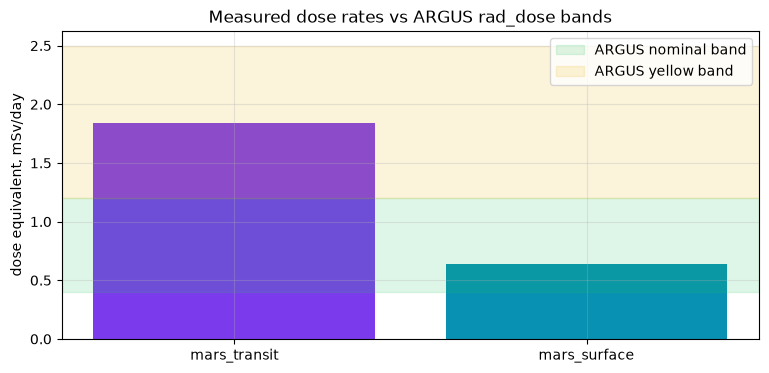

In [5]:
fig, ax = plt.subplots()
ax.bar(eq.environment, eq.dose_rate_msv_per_day, color=['#7c3aed', '#0891b2'])
ax.axhspan(0.4, 1.2, color='#22c55e', alpha=0.15, label='ARGUS nominal band')
ax.axhspan(1.2, 2.5, color='#eab308', alpha=0.15, label='ARGUS yellow band')
ax.set_ylabel('dose equivalent, mSv/day'); ax.set_title('Measured dose rates vs ARGUS rad_dose bands'); ax.legend()
plt.show()

### Findings (traditional analysis)
1. The cruise rate measured by MSL RAD (1.84 mSv/day) falls in ARGUS's **yellow** band. With today's fixed thresholds, every normal day of a Mars transit would show as "caution". The bands need to depend on location (REQ-07). The location is already stored per astronaut, so this is a spec change to `METRIC_THRESHOLDS`, not a data problem.
2. The Mars-surface rate (0.64 mSv/day) sits in the nominal band.
3. The illustrative 860-day mission exceeds the 600 mSv career limit. Cumulative dose (`dose_rate` summed over the mission) should become a tracked, derived metric next to the daily rate. The data is already in `observations`.

In [6]:
table = eq[['environment', 'dose_rate_msv_per_day', 'days_to_career_limit', 'argus_status']].to_markdown(index=False) + '\n\n' + profile.to_markdown(index=False)
ai = summarize('Radiation dose rates vs ARGUS thresholds and the 600 mSv career limit', table)
print(ai['text'] if ai else 'No AI provider reachable: the computed tables above are the result.')
if ai: print(f"\n(model: {ai['model']})")

No AI provider reachable: the computed tables above are the result.
